# Real magnetic microscopy: from field map to grain magnetization

We actively reconstruct the entire measured 600×960 quantum-diamond-microscope image from a rock thin section. The input is upward magnetic induction at 5 µm above the surface, with 2.35 µm pixel spacing. Unknowns are buried grain centres and signed vector magnetic moments. There is no independent physical ground truth. The archived upstream measurement is labelled as a standard-method comparison throughout.

## Physics and inversion

For displacement vector **R** from a grain to a sensor and magnetic moment **m**, the field is $B_z=\mu_0/(4\pi)[3R_z(\mathbf m\cdot\mathbf R)/|R|^5-m_z/|R|^3]$. Here coordinates are metres, moments A m², and induction tesla. Local functions convert the supplied micrometres/nanotesla explicitly. Upward continuation multiplies Fourier coefficients by $\exp(-h|\mathbf k|)$, where h=5 µm and **k** is angular spatial frequency. The local Euler equation $(\mathbf r-\mathbf p)\cdot
abla f=3(b-f)$ estimates grain position **p** and field background b; the three moment components then follow from a linear least-squares fit.

We retain the complete published real-data algorithm: continuation, derivative/TGA computation, ten-scale LoG detection, Euler localization, vector-moment fit, and rejection of above-surface centres. Quality filtering is an interpretation comparison, not a substitute output.

In [1]:
from pathlib import Path
import os,sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.visualization import review
field,x,y=load_data()
started=time.perf_counter()
fresh=reconstruct(field,x,y)
runtime=time.perf_counter()-started
positions,moments,bases,scores,windows,covariance,prepared,detected=fresh
Path('output').mkdir(exist_ok=True)
np.savez_compressed('output/reconstruction.npz',positions=positions[None],moments=moments[None])
np.savez_compressed('notebooks/reference_outputs/cleaned_measurements.npz',positions=positions[None],moments=moments[None],scores=scores,runtime_s=runtime)
upstream=np.load('notebooks/reference_outputs/upstream.npz',allow_pickle=False)
print(f'Fresh complete reconstruction: {runtime:.4f} s; detected {len(detected)}, retained {len(positions)} sources')

Fresh complete reconstruction: 1.1004 s; detected 100, retained 75 sources


## Acquisition, preprocessing and field residuals

The maps below show measured and continued induction, gradient amplitude, detection contrast, the sum of recovered dipoles, and its residual against the continued observations. Units are nT for induction/residual and nT/µm for gradient amplitude. The full-image prediction uses all retained dipoles without their individually fitted local constant backgrounds, matching the upstream diagnostic; its residual therefore includes background and interactions among local fits.

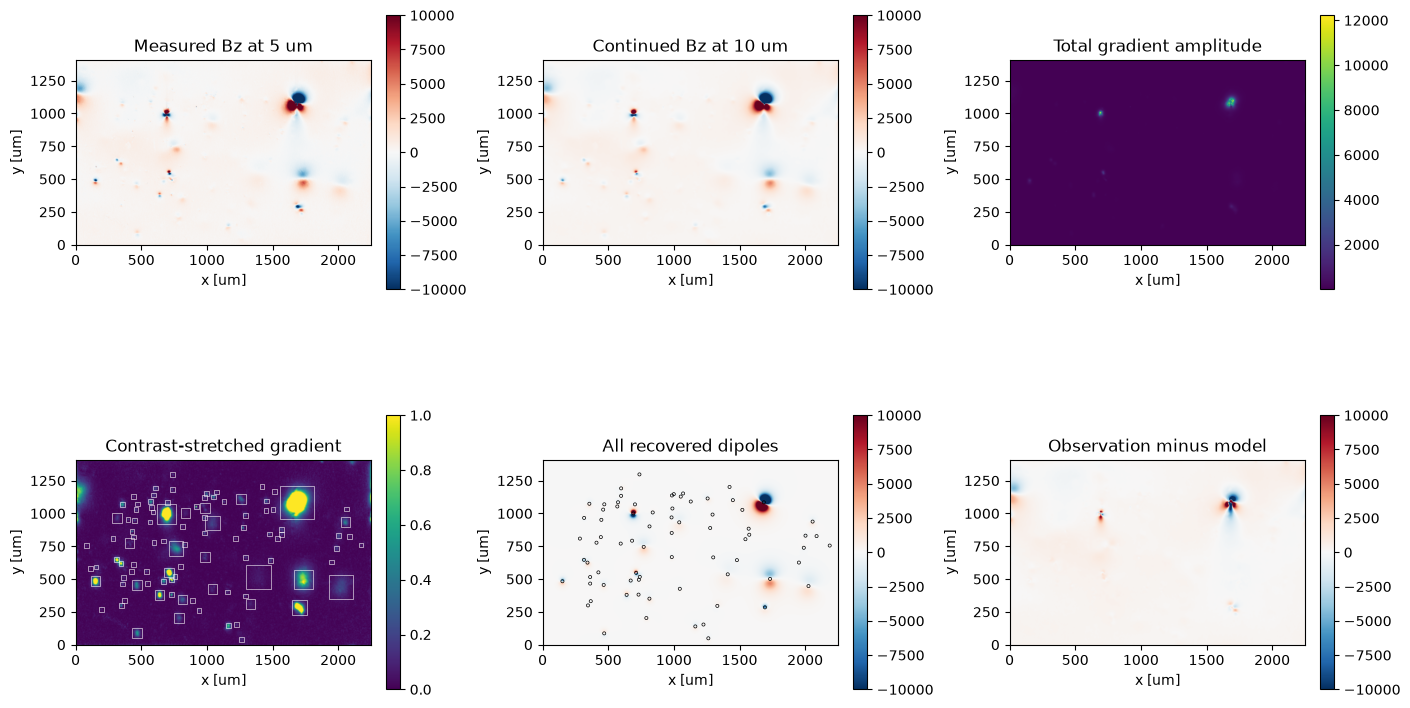

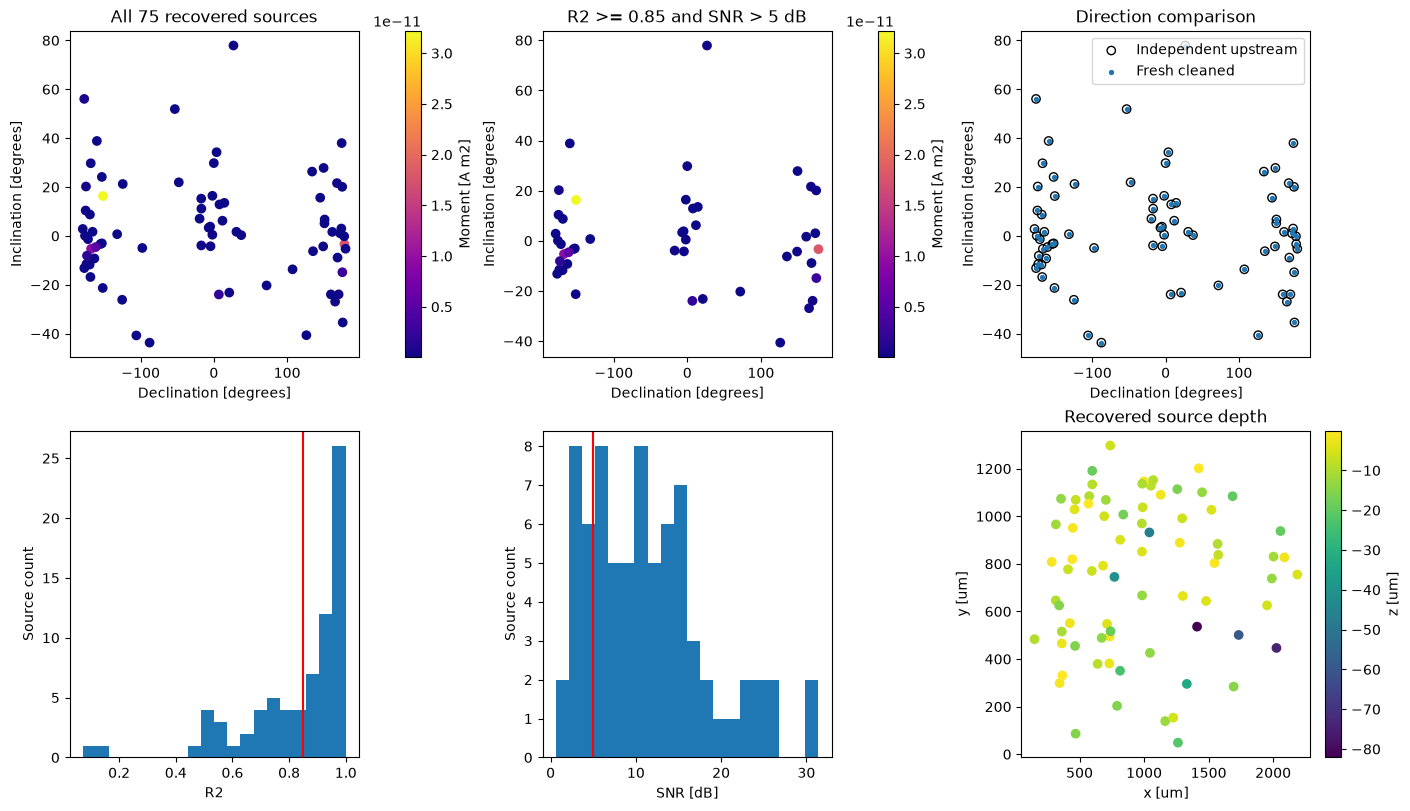

In [2]:
fig_field,fig_directions=review(field,x,y,fresh,upstream)
plt.show()

## Magnetic directions and quality groups

The second figure preserves both scientific comparison groups from the upstream real-data notebook: all recovered grains and the subset with R²≥0.85 and SNR>5 dB. Direction scatter replaces stereographic projection to avoid a plotting-only dependency; it preserves signed inclination/declination, moment-amplitude colour, and group membership. The upstream/fresh overlay and R²/SNR histograms distinguish reproduced results from archived values. Inclination is positive downward; declination is measured from +y toward +x.

The source paper verbally calls SNR=5 a fivefold signal/noise ratio, but its executable statistic is 10 log10(signal variance/residual variance). We preserve and label the executable dB definition. Higher-order grain fields and overlapping sources explain poor-fit dipoles; passing the standard-method comparison does not validate their physical accuracy.

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "position_rmse_um": 8.778175159062668e-13,
    "moment_relative_l2": 4.508011256644531e-14
  },
  "thresholds": {
    "position_rmse_um": {
      "comparison": "<=",
      "boundary": 1e-07
    },
    "moment_relative_l2": {
      "comparison": "<=",
      "boundary": 1e-07
    }
  },
  "errors": []
}
Source group | Independent upstream | Fresh cleaned
All buried sources | 75 | 75
R2 >= 0.85 and SNR > 5 dB | 46 | 46


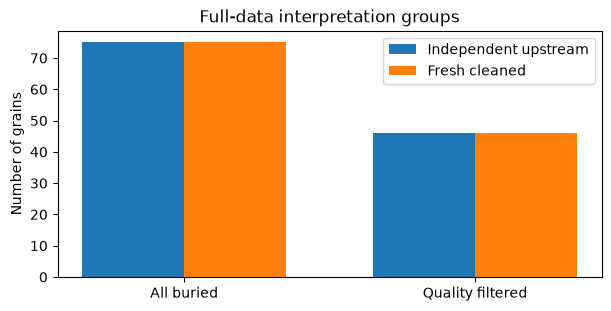

In [3]:
spec=importlib.util.spec_from_file_location('standalone_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exit_code=judge.evaluate('output/reconstruction.npz')
assert exit_code==0,report
print(json.dumps(report,indent=2))
print('Source group | Independent upstream | Fresh cleaned')
print('All buried sources |',len(upstream['scores']),'|',len(scores))
up_good=(upstream['scores'][:,0]>=.85)&(upstream['scores'][:,1]>5)
good=(scores[:,0]>=.85)&(scores[:,1]>5)
print('R2 >= 0.85 and SNR > 5 dB |',int(up_good.sum()),'|',int(good.sum()))
fig,ax=plt.subplots(figsize=(6,3),layout='constrained')
axis=np.arange(2);width=.35
ax.bar(axis-width/2,[len(upstream['scores']),up_good.sum()],width,label='Independent upstream')
ax.bar(axis+width/2,[len(scores),good.sum()],width,label='Fresh cleaned')
ax.set(xticks=axis,xticklabels=['All buried','Quality filtered'],ylabel='Number of grains',title='Full-data interpretation groups')
ax.legend();plt.show()

## Local anomaly checks

The first five detected buried sources retain the upstream local-data / all-source-model / residual comparison. Common colour scales within each row show imperfect dipole approximation and interaction from nearby sources rather than hiding these discrepancies.

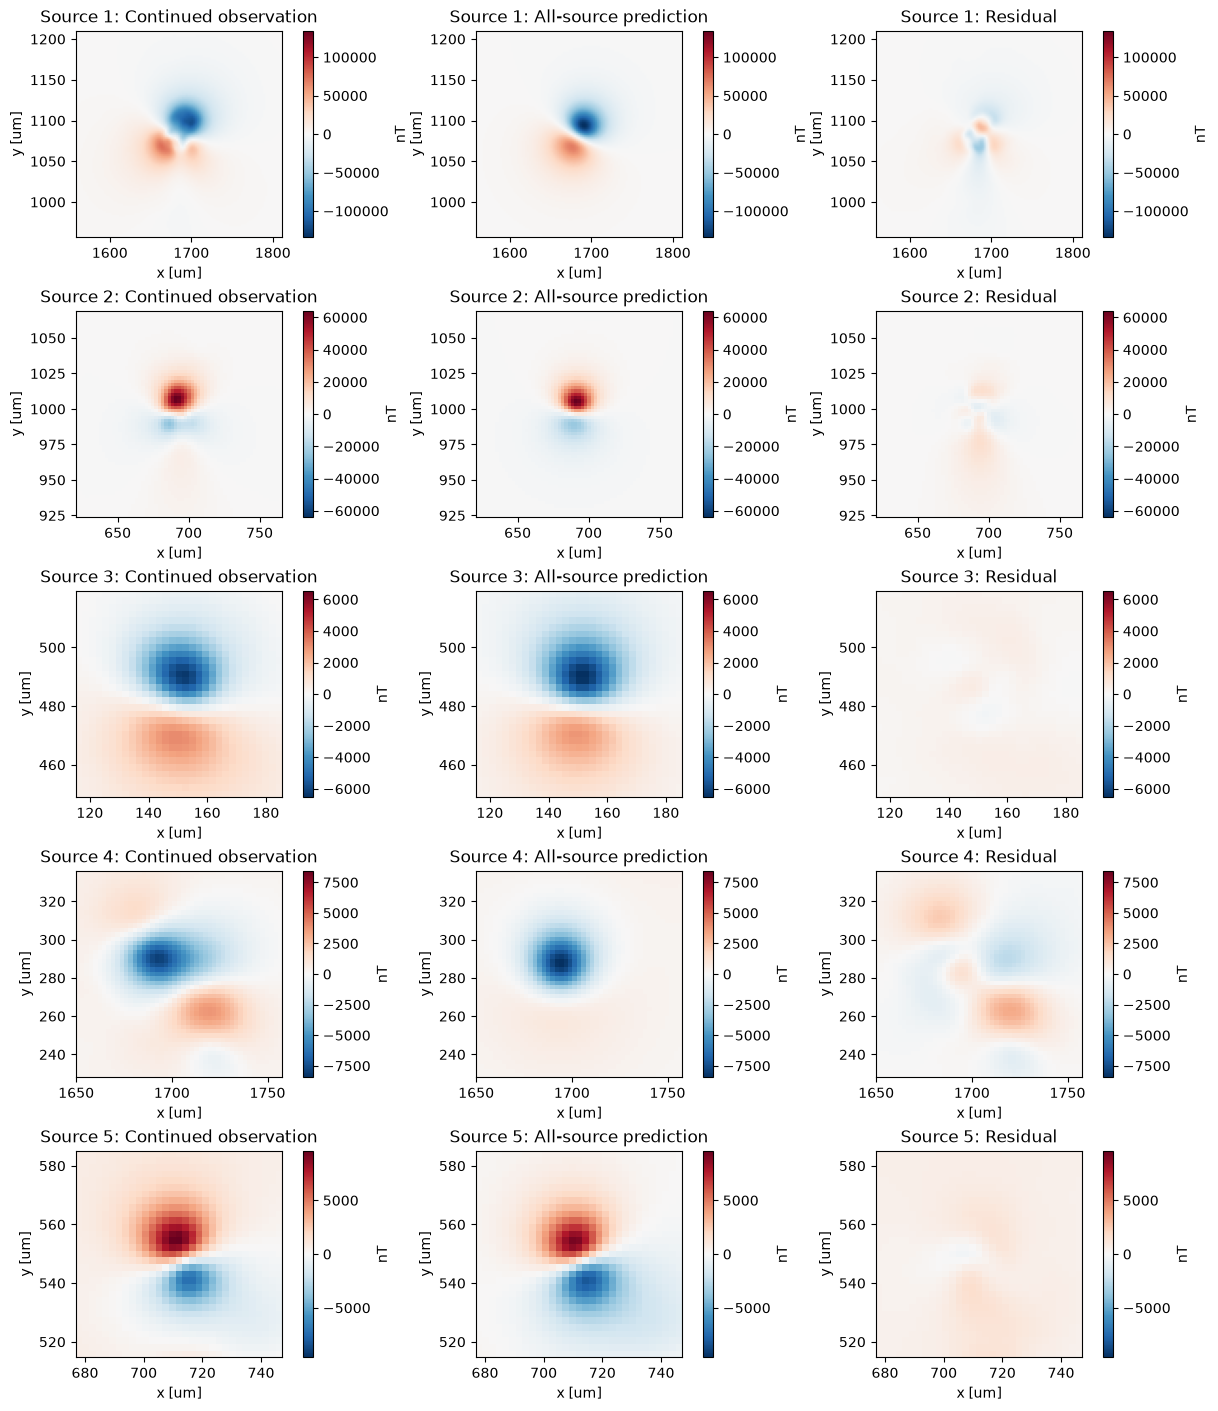

In [4]:
from src.physics_model import forward
xx,yy=np.meshgrid(x,y)
combined=forward(xx,yy,10.,positions,moments)
fig,axes=plt.subplots(5,3,figsize=(12,14),layout='constrained')
for row,window in enumerate(windows[:5]):
    ix=(x>=window[0])&(x<=window[1]);iy=(y>=window[2])&(y<=window[3]);sel=np.ix_(iy,ix)
    local=prepared[0][sel];model=combined[sel];limit=max(abs(local).max(),abs(model).max())
    for ax,array,title in zip(axes[row],(local,model,local-model),('Continued observation','All-source prediction','Residual')):
        im=ax.imshow(array,origin='lower',cmap='RdBu_r',vmin=-limit,vmax=limit,extent=(x[ix][0],x[ix][-1],y[iy][0],y[iy][-1]))
        ax.set(title=f'Source {row+1}: {title}',xlabel='x [um]',ylabel='y [um]');fig.colorbar(im,ax=ax,label='nT')
plt.show()

## Conclusion

The fresh local method reproduces the standard upstream source positions and vector moments on the same real observations. The acquisition, all-source field comparison, signed magnetic directions, quality-filter groups and numeric evaluator results are shown explicitly. These results establish reproducibility of this particular dipolar interpretation; source depth/amplitude ambiguity, multipolar grains, and finite-window interaction remain physical limitations.